In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import roc_auc_score
from sklearn.metrics import auc

In [2]:
features = ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11']

# only load the columns I need, so it uses less memory
data = pd.read_parquet(
    'uplift_clean.parquet',
    columns=features + ['treatment', 'conversion', 'visit', 'exposure']
).reset_index(drop=True)

In [3]:
data.shape

(13979592, 16)

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13979592 entries, 0 to 13979591
Data columns (total 16 columns):
 #   Column      Dtype  
---  ------      -----  
 0   f0          float32
 1   f1          float32
 2   f2          float32
 3   f3          float32
 4   f4          float32
 5   f5          float32
 6   f6          float32
 7   f7          float32
 8   f8          float32
 9   f9          float32
 10  f10         float32
 11  f11         float32
 12  treatment   int8   
 13  conversion  int8   
 14  visit       int8   
 15  exposure    int8   
dtypes: float32(12), int8(4)
memory usage: 693.3 MB


In [5]:
data.head()

,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
0,12.616364,10.059654,8.976429,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
1,12.616364,10.059654,9.002689,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
2,12.616364,10.059654,8.964775,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
3,12.616364,10.059654,9.002801,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
4,12.616364,10.059654,9.037999,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0


### Research Question

Given a fixed marketing budget, which customers should be targeted to maximize incremental conversions, rather than simply targeting customers who are most likely to purchase?


### Project Objectives

**1.** Predict how much each customer's behavior is expected to change because of the marketing treatment.

**2.** Target customers with the highest expected incremental conversion.

### Key Variables

- **Dependent Variable**: conversion
- **Treatment Variable**: treatment
- **Features**: f0–f11

`treatment = 1` means the customer was *randomly assigned* to the campaign. It does not mean they actually saw an ad (that is the `exposure` column). So the effects I estimate are the effects of *being targeted*, also called intention-to-treat (ITT) effects. I will also estimate the effect of *actually seeing the ad*.

### 1. Data Validation Checks

- First, I look at the share of customers in the treatment group and compare the conversion, visit, and exposure rates between the treatment and control groups.

In [6]:
print('Share of customers in treatment group:', data['treatment'].mean())

data.groupby('treatment')[['conversion', 'visit', 'exposure']].mean()

Share of customers in treatment group: 0.8500001287591226


,conversion,visit,exposure
treatment,,,
0,0.001938,0.038201,0.000000
1,0.003089,0.048543,0.036037


- Nobody in the control group should have seen an ad, so this should print 0.

In [7]:
control_group = data[data['treatment'] == 0]

print('Exposed customers in control group:', control_group['exposure'].sum())

Exposed customers in control group: 0


- Next, I check whether the two groups of customers are similar using the **standardized mean difference (SMD)** for each feature.

  **SMD = (mean in group 1 − mean in group 0) / average standard deviation**

- Dividing by the standard deviation puts the features on a common scale, making them easier to compare. A common rule of thumb is that an **absolute SMD below 0.1** indicates good balance between the groups.

In [8]:
def standardized_mean_difference(data, group_column, columns):
    group_1 = data[data[group_column] == 1][columns]
    group_0 = data[data[group_column] == 0][columns]

    difference_in_means = group_1.mean() - group_0.mean()
    average_std = np.sqrt((group_1.var() + group_0.var()) / 2)

    return difference_in_means / average_std

- For each feature, the function measures how different the treatment and control groups are, relative to the amount of variation in that feature.
- I compare two groups:
  1. **Treatment vs. control:** Since treatment was randomly assigned, these two groups should look similar, so the SMDs should be close to 0.
  2. **Exposed vs. unexposed customers within the treatment group:** Seeing an ad was not random, so these customers may be quite different from each other. This is why I can't simply use the unexposed treated customers as the control group.

In [9]:
treatment_group = data[data['treatment'] == 1]

balance = pd.DataFrame({
    'treatment vs control': standardized_mean_difference(data, 'treatment', features),
    'exposed vs unexposed (treated only)': standardized_mean_difference(treatment_group, 'exposure', features),
})

# with this many customers, even a small SMD can be far larger than chance
print('Approximate standard error of a treatment vs control SMD:',
      np.sqrt(1 / len(treatment_group) + 1 / len(control_group)))

balance.round(3)

Approximate standard error of a treatment vs control SMD: 0.000749027586326405


,treatment vs control,exposed vs unexposed (treated only)
f0,-0.007,-0.850
f1,0.006,0.257
f2,-0.005,0.022
f3,-0.049,-1.450
f4,0.004,0.361
f5,-0.031,-0.642
f6,-0.041,-1.402
f7,0.020,0.584
f8,-0.016,-0.853
f9,0.024,0.885


### 1.1 Average effect of being targeted and of seeing the ad

Since I cannot directly compare exposed and unexposed customers, I use the random assignment instead. Nobody in the control group saw an ad, so the difference in conversion rates between the treatment and control groups reflects the effect of targeting customers with the campaign. Dividing this difference by the share of treated customers who actually saw an ad gives the average effect of seeing the ad.

In [10]:
rates = data.groupby('treatment')['conversion'].mean()
itt = rates[1] - rates[0]
exposure_rate = treatment_group['exposure'].mean()

print('Effect of being targeted (ITT):', itt)
print('Share of treated customers who saw an ad:', exposure_rate)
print('Effect of seeing the ad:', itt / exposure_rate)

Effect of being targeted (ITT): 0.0011518730521316279
Share of treated customers who saw an ad: 0.036036727482199896
Effect of seeing the ad: 0.031963863885825596


### 1.2 Propensity score matching within the treatment group

The SMD table above already shows that exposure was not random. Here I look at the same question in a second way and then try to adjust for it.

- A **propensity score** is a customer's predicted chance of seeing an ad, based on their features.
- **Matching** pairs each exposed customer with an unexposed customer who has a similar propensity score, so that the two groups I compare look alike on the features.

I do this in five steps: (1) propensity model, (2) overlap, (3) matching, (4) balance after matching, and (5) comparison with the randomized estimate.

I only use `f0`–`f11`. `visit` and `conversion` happen after assignment, so they cannot be used to predict exposure.

This analysis does not change the uplift models below, which estimate the effect of being targeted.

**Step 1: Propensity model**

- I train a model that predicts `exposure` from the features. I use treated customers only, because nobody in the control group could be exposed.
- The predictions are **out-of-fold**: the data is split into five parts, and each customer's propensity comes from a model trained on the other four parts. This stops the model from simply memorizing who was exposed.
- I summarize the model with the **AUC**. This is the chance that the model gives a randomly chosen exposed customer a higher score than a randomly chosen unexposed customer.
    - If exposure were random, the features could not predict it and the AUC would be about 0.5.
    - An AUC of 1 would mean that exposure can be predicted perfectly from the features.
- With about 11.9 million treated customers, this step takes a while.

In [11]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.neighbors import NearestNeighbors

treated = treatment_group.copy()

propensity_model = HistGradientBoostingClassifier(
    learning_rate=0.05,
    max_iter=300,
    min_samples_leaf=200,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=20,
    random_state=42
)

start = time.time()

# Out-of-fold predictions: each customer's propensity comes from a model that did not see them
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

treated['propensity'] = cross_val_predict(
    propensity_model,
    treated[features],
    treated['exposure'],
    cv=folds,
    method='predict_proba'
)[:, 1]

print('Minutes:', round((time.time() - start) / 60, 1))
print('Propensity model AUC:', roc_auc_score(treated['exposure'], treated['propensity']))

Minutes: 30.0
Propensity model AUC: 0.9213243125558171


**Step 2: Overlap**

- Matching only works if, for each exposed customer, there are unexposed customers with a similar propensity. If the two groups had completely separate propensities, there would be nobody to match with.
- I plot the propensities of both groups on the **log-odds** scale, log(p / (1 − p)). Most propensities are very close to 0, so on the ordinary scale they would be squeezed together.

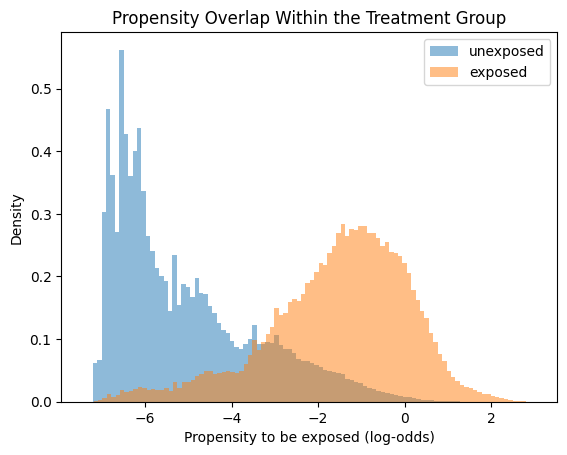

In [12]:
clipped = treated['propensity'].clip(1e-6, 1 - 1e-6)
treated['logit'] = np.log(clipped / (1 - clipped))

exposed = treated[treated['exposure'] == 1]
unexposed = treated[treated['exposure'] == 0]

plt.hist(unexposed['logit'], bins=100, density=True, alpha=0.5, label='unexposed')
plt.hist(exposed['logit'], bins=100, density=True, alpha=0.5, label='exposed')
plt.xlabel('Propensity to be exposed (log-odds)')
plt.ylabel('Density')
plt.title('Propensity Overlap Within the Treatment Group')
plt.legend()
plt.show()

**Step 3: Matching**

- For each exposed customer, I take the unexposed customer with the closest propensity on the log-odds scale (1 nearest neighbor).
- Matching is **with replacement**: one unexposed customer can be matched to several exposed customers. This gives closer matches in the regions where unexposed customers are scarce.
- I use a **caliper**: I drop exposed customers whose closest match is further away than 0.2 standard deviations of the log-odds propensity. This is a common rule of thumb to avoid poor matches. If many exposed customers were dropped, the matched estimate would only describe the ones that remain.
- **Ties:** many customers have exactly the same propensity, so they would all be matched to the same unexposed customer. To avoid this, I add a tiny random number to each log-odds value, so ties are broken at random. The noise is much smaller than the caliper, so it does not change which matches are allowed.

In [13]:
caliper = 0.2 * treated['logit'].std()

# tiny random noise (much smaller than the caliper) to break ties
rng = np.random.default_rng(42)
unexposed_logit = unexposed[['logit']].to_numpy() + rng.uniform(-1e-6, 1e-6, size=(len(unexposed), 1))
exposed_logit = exposed[['logit']].to_numpy() + rng.uniform(-1e-6, 1e-6, size=(len(exposed), 1))

neighbors = NearestNeighbors(n_neighbors=1)
neighbors.fit(unexposed_logit)

distance, position = neighbors.kneighbors(exposed_logit)
distance = distance[:, 0]
position = position[:, 0]

within_caliper = distance <= caliper

matched_exposed = exposed[within_caliper]
matched_unexposed = unexposed.iloc[position[within_caliper]]

times_used = matched_unexposed.index.value_counts()

print('Exposed customers:', len(exposed))
print('Share matched within the caliper:', within_caliper.mean())
print('Different unexposed customers used:', len(times_used))
print('Most times one unexposed customer was used:', times_used.max())

Exposed customers: 428212
Share matched within the caliper: 1.0
Different unexposed customers used: 330105
Most times one unexposed customer was used: 44


**Step 4: Balance after matching**

- The purpose of matching is to make the two groups look alike on the features. To check whether it did, I reuse `standardized_mean_difference` on the matched pairs and put the result next to the SMDs from before matching.
- If matching worked, all SMDs should now be below 0.1 in absolute value.

In [14]:
matched = pd.concat([matched_exposed, matched_unexposed])

balance_matching = pd.DataFrame({
    'before matching': standardized_mean_difference(treated, 'exposure', features),
    'after matching': standardized_mean_difference(matched, 'exposure', features),
})

print('Largest absolute SMD after matching:', balance_matching['after matching'].abs().max())

balance_matching.round(3)

Largest absolute SMD after matching: 0.011355403810739517


,before matching,after matching
f0,-0.850,0.011
f1,0.257,-0.001
f2,0.022,0.010
f3,-1.450,0.002
f4,0.361,0.002
f5,-0.642,-0.001
f6,-1.402,-0.003
f7,0.584,0.005
f8,-0.853,-0.011
f9,0.885,0.008


**Step 5: Comparison with the randomized estimate**

- I compare three estimates of the effect of seeing the ad on the customers who saw it:
    1. **Naive:** exposed minus unexposed treated customers, with no adjustment.
    2. **Matched:** exposed minus their matched unexposed customers.
    3. **Randomized comparison (ITT / exposure rate):** the treatment vs. control difference from the section above, divided by the share of treated customers who saw an ad. Because the company assigned customers to treatment and control at random, the two groups are alike apart from chance, including in things the features do not record. So this estimate does not depend on the features, and I use it as the benchmark for matching.
- This is the real test of matching. If the features captured everything that makes exposed customers different, the matched estimate should be close to the randomized one. If it is still clearly larger, exposed customers differ in ways the features do not record.
- The standard errors are approximate. For the matched estimate, I account for unexposed customers being used more than once, but not for the propensity itself being estimated.

In [15]:
# 1. Naive comparison
naive = exposed['conversion'].mean() - unexposed['conversion'].mean()

# 2. Matched comparison
rate_exposed = matched_exposed['conversion'].mean()
rate_matched = matched_unexposed['conversion'].mean()
matched_effect = rate_exposed - rate_matched

n_matched = len(matched_exposed)
matched_se = np.sqrt(
    rate_exposed * (1 - rate_exposed) / n_matched
    + rate_matched * (1 - rate_matched) * (times_used ** 2).sum() / n_matched ** 2
)

# 3. Randomized benchmark (treats the exposure rate as known, which it nearly is at this sample size)
experiment_effect = itt / exposure_rate
itt_se = np.sqrt(
    rates[1] * (1 - rates[1]) / len(treatment_group)
    + rates[0] * (1 - rates[0]) / len(control_group)
)
experiment_se = itt_se / exposure_rate

effect_comparison = pd.DataFrame({
    'estimate': [naive, matched_effect, experiment_effect],
    'standard error': [np.nan, matched_se, experiment_se],
}, index=['naive (exposed - unexposed)', 'propensity score matching', 'randomized comparison (ITT / exposure rate)'])

effect_comparison['lower 95%'] = effect_comparison['estimate'] - 1.96 * effect_comparison['standard error']
effect_comparison['upper 95%'] = effect_comparison['estimate'] + 1.96 * effect_comparison['standard error']

effect_comparison.round(4)

,estimate,standard error,lower 95%,upper 95%
naive (exposed - unexposed),0.0526,NaN,NaN,NaN
propensity score matching,0.0444,0.0004,0.0436,0.0452
randomized comparison (ITT / exposure rate),0.0320,0.0010,0.0301,0.0338


### 1.3 Further tests of whether exposure was random

The SMD table compares the average of each feature. Here I add four more tests. The first uses the outcome and the control group; the other three use the features.

1. **Unexposed treated customers vs. control.** Do treated customers who never saw an ad behave like the control group?
2. **Joint test.** Do the twelve features together predict exposure?
3. **Permutation test on the propensity AUC.** Could the AUC of 0.92 have happened by chance?
4. **Kolmogorov–Smirnov tests.** Does the whole distribution of each feature differ, not only its average?

This section reuses `treated`, `exposed`, `unexposed` and `propensity_model` from the matching section above.

With about 11.9 million treated customers, even very small differences give tiny p-values. So for each test I also report a measure of how large the difference is.

**Test 1: Unexposed treated customers vs. control**

- **Idea.** The control group is a random sample of all customers, and none of them saw an ad. The unexposed treated customers did not see an ad either. If exposure were random, they would also be like a random sample of all customers, so the two groups should have the same conversion and visit rates.
- **What a difference means.** If the rates differ, the customers who were exposed (and are therefore missing from the unexposed group) were different to begin with. If the unexposed treated rate is *lower* than the control rate, the exposed customers were more likely to convert or visit even without the ad.
- **How the test works.** I use a z-test for two rates. It divides the difference in rates by its standard error. If there were no real difference, z would fall between −1.96 and 1.96 in 95% of cases. The p-value is the chance of seeing a difference at least this large if the true rates were equal.
- **Why this test is different.** It uses the outcome directly, so it also picks up differences in things that `f0`–`f11` do not record. The other three tests cannot do that.
- **Assumption.** Like the ITT / exposure rate estimate, it assumes that being assigned to the campaign affects the outcome only through seeing an ad.

In [16]:
from scipy.stats import norm, chi2, ks_2samp


def compare_rates(group_a, group_b, outcome):
    rate_a = group_a[outcome].mean()
    rate_b = group_b[outcome].mean()

    standard_error = np.sqrt(
        rate_a * (1 - rate_a) / len(group_a)
        + rate_b * (1 - rate_b) / len(group_b)
    )
    z = (rate_a - rate_b) / standard_error

    return {
        'unexposed treated': rate_a,
        'control': rate_b,
        'difference': rate_a - rate_b,
        'z': z,
        'p-value': 2 * norm.sf(abs(z)),
    }


control_comparison = pd.DataFrame({
    'conversion': compare_rates(unexposed, control_group, 'conversion'),
    'visit': compare_rates(unexposed, control_group, 'visit'),
}).T

control_comparison

,unexposed treated,control,difference,z,p-value
conversion,0.001194,0.001938,-0.000743,-23.201157,4.432376e-119
visit,0.034861,0.038201,-0.003340,-23.350268,1.369558e-120


**Follow-up to Test 1: do the two groups differ on the features?**

- Test 1 showed that unexposed treated customers and the control group have different conversion and visit rates. Here I check whether they also differ on the features, using the same SMD as in Section 1.
- Exposed customers are only 3.6% of the treatment group, so removing them should change the feature averages only slightly. I expect most SMDs to be below 0.1.

In [17]:
unexposed_vs_control = pd.concat([
    unexposed.assign(group=1),
    control_group.assign(group=0),
])

standardized_mean_difference(unexposed_vs_control, 'group', features).round(3)

f0     0.019
f1    -0.005
f2    -0.005
f3     0.033
f4    -0.014
f5     0.021
f6     0.017
f7    -0.011
f8     0.015
f9    -0.021
f10   -0.005
f11    0.021
dtype: float32

**Test 2: Joint test of all features**

- **Idea.** The SMD table looks at one feature at a time. This test checks whether all twelve features together help predict who was exposed.
- **How the test works.** I fit a logistic regression that predicts `exposure` from the twelve features and compare it with a model that uses no features and gives everyone the same probability. This is a **likelihood ratio test**. The statistic measures how much better the model with features fits the data.
- **How to read it.** If the features had nothing to do with exposure, the statistic would be around 12 (one per feature), and values above 21 would occur only 5% of the time. The p-value is the chance of a statistic at least this large if the features did not matter.
- **Size of the difference.** The pseudo R² shows how much the features improve the fit. It is 0 if they do not help at all and gets closer to 1 the better they predict exposure.

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import log_loss

# Standardizing helps the model converge and does not change the test
features_scaled = StandardScaler().fit_transform(treated[features])

# A very large C switches off regularization, so this is an ordinary logistic regression
logistic_model = LogisticRegression(C=1e10, max_iter=1000)
logistic_model.fit(features_scaled, treated['exposure'])

predicted = logistic_model.predict_proba(features_scaled)[:, 1]
no_features = np.full(len(treated), treated['exposure'].mean())

log_likelihood_model = -log_loss(treated['exposure'], predicted, normalize=False)
log_likelihood_null = -log_loss(treated['exposure'], no_features, normalize=False)

likelihood_ratio = 2 * (log_likelihood_model - log_likelihood_null)

print('Likelihood ratio statistic:', likelihood_ratio)
print('Degrees of freedom:', len(features))
print('p-value:', chi2.sf(likelihood_ratio, df=len(features)))
print('Pseudo R-squared:', 1 - log_likelihood_model / log_likelihood_null)

Likelihood ratio statistic: 1162658.6525718588
Degrees of freedom: 12
p-value: 0.0
Pseudo R-squared: 0.31534973930969723


**Test 3: Permutation test on the propensity AUC**

- **Idea.** The propensity model in Step 1 has an AUC of 0.92. This test asks whether an AUC that high could happen by chance if exposure had nothing to do with the features.
- **How the test works.** I shuffle the `exposure` column, which breaks any link between exposure and the features but keeps the same number of exposed customers. Then I refit the propensity model and record its AUC. I repeat this 100 times. The shuffled AUCs show which values can occur by chance.
- **How to read it.** The p-value is the share of shuffles with an AUC at least as high as the real one. With 100 shuffles, the smallest possible p-value is about 0.01.
- **Practical detail.** Refitting the model 100 times on 11.9 million customers would take far too long. So I use a random subset of 500,000 treated customers and one 70/30 split instead of five folds. The AUC on the real data is recomputed in the same way on the same subset, so the comparison is fair.

In [19]:
from sklearn.base import clone

# random subset of treated customers, to keep the 100 refits manageable
perm_data = treated.sample(n=min(500_000, len(treated)), random_state=42)


def holdout_auc(exposure_labels):
    X_fit, X_holdout, labels_fit, labels_holdout = train_test_split(
        perm_data[features], exposure_labels,
        test_size=0.3,
        random_state=42,
        stratify=exposure_labels
    )

    model = clone(propensity_model)
    model.fit(X_fit, labels_fit)

    return roc_auc_score(labels_holdout, model.predict_proba(X_holdout)[:, 1])


start = time.time()

real_labels = perm_data['exposure'].to_numpy()
real_auc = holdout_auc(real_labels)

n_shuffles = 100
random_generator = np.random.default_rng(42)

shuffled_aucs = []
for i in range(n_shuffles):
    shuffled_labels = random_generator.permutation(real_labels)
    shuffled_aucs.append(holdout_auc(shuffled_labels))

shuffled_aucs = np.array(shuffled_aucs)

print('Minutes:', round((time.time() - start) / 60, 1))
print('AUC on the real data:', real_auc)
print('AUC after shuffling (min, mean, max):', shuffled_aucs.min(), shuffled_aucs.mean(), shuffled_aucs.max())
print('p-value:', (1 + (shuffled_aucs >= real_auc).sum()) / (1 + n_shuffles))

Minutes: 4.2
AUC on the real data: 0.9190145105588251
AUC after shuffling (min, mean, max): 0.49085980625177494 0.50026775270168 0.510331640295054
p-value: 0.009900990099009901


**Test 4: Kolmogorov–Smirnov (KS) test for each feature**

- **Idea.** The SMD only compares averages. Two groups can have the same average but a different spread or shape, and the SMD would miss that. The KS test compares the whole distribution of a feature.
- **How the test works.** For each feature and each possible value, I look at the share of customers at or below that value in the exposed group and in the unexposed group. The **KS statistic** is the largest gap between these two shares.
- **How to read it.** The statistic ranges from 0 (identical distributions) to 1 (no overlap at all). The p-value is the chance of a gap at least this large if both groups came from the same distribution.
- I show the SMD from Section 1 next to it for comparison.

In [20]:
ks_results = []

for feature in features:
    result = ks_2samp(exposed[feature], unexposed[feature])
    ks_results.append({
        'feature': feature,
        'KS statistic': result.statistic,
        'p-value': result.pvalue,
    })

ks_results = pd.DataFrame(ks_results).set_index('feature')
ks_results['SMD'] = balance['exposed vs unexposed (treated only)']

ks_results.sort_values('KS statistic', ascending=False).round(4)

,KS statistic,p-value,SMD
feature,,,
f3,0.6545,0.0,-1.4503
f6,0.5258,0.0,-1.4023
f8,0.4383,0.0,-0.8532
f0,0.4371,0.0,-0.8503
f9,0.4008,0.0,0.8855
f2,0.3367,0.0,0.0225
f7,0.2631,0.0,0.5836
f5,0.2631,0.0,-0.6423
f4,0.1643,0.0,0.3608


In [21]:
import gc

del treated, exposed, unexposed, matched, matched_exposed, matched_unexposed
del unexposed_logit, exposed_logit
del unexposed_vs_control, features_scaled, predicted, no_features, perm_data
del treatment_group, control_group
gc.collect()

14078

### 2. Train / Validation / Test Split

1. **Train (60%)**: used to fit the models.
2. **Validation (20%)**: used to choose model settings.
3. **Test (20%)**: used only at the end to compare the models fairly.

- I stratify by treatment and conversion together (e.g., `'1_0'` = treated, did not convert). Since conversions are rare, this helps keep a similar proportion of converters in each split.

In [22]:
X = data[features]
T = data['treatment']
y = data['conversion']

strata = T.astype(str) + '_' + y.astype(str)

strata.value_counts()

1_0    11845944
0_0     2092874
1_1       36711
0_1        4063
Name: count, dtype: int64

In [23]:
# Training data (60% train, 40% left over).
X_train, X_temp, T_train, T_temp, y_train, y_temp = train_test_split(
    X, T, y,
    test_size=0.4,
    random_state=42,
    stratify=strata
)

# Validation and Test sets from the 40% left over data, 50/50 split.
X_val, X_test, T_val, T_test, y_val, y_test = train_test_split(
    X_temp, T_temp, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=strata.loc[X_temp.index]
)

print('Train size:', len(X_train))
print('Validation size:', len(X_val))
print('Test size:', len(X_test))
print('Control conversions in train, validation and test:',
      y_train[T_train == 0].sum(), y_val[T_val == 0].sum(), y_test[T_test == 0].sum())

Train size: 8387755
Validation size: 2795918
Test size: 2795919
Control conversions in train, validation and test: 2438 812 813


### 3. Functions to Evaluate Uplift Models

The `uplift_curve` function helps to evaluate how well the models rank customers.

First, I sort customers from highest to lowest predicted uplift. I then move down the list and keep running totals of treated customers, control customers, and conversions.

At each point, I calculate:

- `uplift`: the difference between the treatment and control conversion rates.

  `uplift`= (treated conversion rate − control conversion rate) among customers targeted so far.

- `incremental_conversions`: the estimated number of additional conversions from targeting the customers considered so far. I calculate this by multiplying the uplift by the number of customers targeted.

  `incremental_conversions`= `uplift` × number of customers targeted

- `qini`: the estimated cumulative number of additional conversions generated by treatment compared with control. I calculate this by comparing the actual treatment conversions with the number of conversions expected if the treated customers had the control group's conversion rate.

I use the Qini curve to measure how well my model identifies customers who are most likely to benefit from treatment.

A good model should rank customers who benefit most from treatment near the top of the list, giving higher uplift and Qini values early in the curve.

In [24]:
def uplift_curve(data, score_column):
    
    # Shuffle first so that customers with the same score end up in random order
    data = data.sample(frac=1, random_state=42)

    # Sort customers from highest to lowest predicted uplift
    data = data.sort_values(score_column, ascending=False, kind='stable')

    is_treated = (data['treatment'] == 1).astype(int)
    is_control = (data['treatment'] == 0).astype(int)
    converted = data['conversion'].astype(int)

    # Running totals as I go down the list
    treated_count = is_treated.cumsum()
    control_count = is_control.cumsum()
    treated_conversions = (converted * is_treated).cumsum()
    control_conversions = (converted * is_control).cumsum()

    curve = pd.DataFrame()
    curve['customers_targeted'] = np.arange(1, len(data) + 1)
    curve['fraction_targeted'] = curve['customers_targeted'] / len(data)

    curve['treated_rate'] = (treated_conversions / treated_count).values
    curve['control_rate'] = (control_conversions / control_count).values
    curve['uplift'] = (curve['treated_rate'] - curve['control_rate']).fillna(0)
    curve['incremental_conversions'] = curve['uplift'] * curve['customers_targeted']

    scaled_control_conversions = control_conversions * treated_count / control_count.clip(lower=1)
    curve['qini'] = (treated_conversions - scaled_control_conversions).values

    return curve

**Function 2: `evaluate_model`** summarizes the curve using a few numbers:

- **Qini AUC**: the area between the model's Qini curve and the random-targeting line, divided by the number of customers. A higher value means the model performs better than random targeting.
- **Uplift@k**: the observed uplift among the top k% of customers ranked by the model.

The calculations are the same as in `uplift_curve` and in `Modeling_sample_2.ipynb`, but `curve_metrics` works on NumPy arrays instead of a DataFrame. That makes it much faster, which matters because the bootstrap below calls it 1,000 times on 2.8 million customers (200 resamples × 5 models).

In [25]:
top_percentages = [5, 10, 20, 30, 50]


def curve_metrics(treatment, conversion, score):
    # the arrays need to be shuffled already, so ties are broken at random
    n = len(score)

    # sort customers from highest to lowest score
    order = np.argsort(-score, kind='stable')
    is_treated = treatment[order].astype(np.int64)
    converted = conversion[order].astype(np.int64)
    is_control = 1 - is_treated

    # running totals as I go down the list
    treated_count = np.cumsum(is_treated)
    control_count = np.cumsum(is_control)
    treated_conversions = np.cumsum(converted * is_treated)
    control_conversions = np.cumsum(converted * is_control)

    # Qini curve, and the gain over the random-targeting line
    qini = treated_conversions - control_conversions * treated_count / np.maximum(control_count, 1)
    fraction_targeted = np.arange(1, n + 1) / n
    gain_over_random = (qini - fraction_targeted * qini[-1]) / n

    results = {'qini_auc': auc(fraction_targeted, gain_over_random)}

    for percentage in top_percentages:
        row = int(n * percentage / 100) - 1
        if treated_count[row] == 0 or control_count[row] == 0:
            results[f'uplift@{percentage}%'] = 0.0
        else:
            results[f'uplift@{percentage}%'] = (treated_conversions[row] / treated_count[row]
                                                - control_conversions[row] / control_count[row])

    return results


def evaluate_model(data, score_column):
    # shuffle once so that customers with the same score end up in random order
    order = np.random.default_rng(42).permutation(len(data))

    treatment = data['treatment'].to_numpy()[order]
    conversion = data['conversion'].to_numpy()[order]
    score = data[score_column].to_numpy()[order]

    return curve_metrics(treatment, conversion, score)

**Function 3: bootstrap intervals** add a 95% confidence interval to each metric.

- I perform bootstrapping by resampling the test customers 200 times (`n_resamples=200`) with replacement, recalculating each metric, and using the middle 95% of the results as the confidence interval.
- `bootstrap_metrics` draws each resample once and evaluates every model on it. So every model is evaluated on the same resamples, which keeps the comparison fair. (In `Modeling_sample_2.ipynb` this was done with `random_state=i` in each function. Drawing once gives the same kind of result and is much faster.)
- `evaluate_with_intervals` then gives each metric with its interval. If a confidence interval includes 0, the result is not clearly different from zero.
- These intervals only reflect uncertainty from which customers ended up in the test set. The models are trained once and not retrained on each resample, so the intervals do not include variation from training (for example, a different train/test split or random seed). The true uncertainty is therefore somewhat larger than shown.

In [26]:
def bootstrap_metrics(data, model_columns, n_resamples=200):
    n = len(data)
    treatment = data['treatment'].to_numpy()
    conversion = data['conversion'].to_numpy()

    resampled_results = {model: [] for model in model_columns}

    for i in range(n_resamples):
        # draw n customers with replacement, the same rows for every model
        rows = np.random.default_rng(i).integers(0, n, size=n)

        for model in model_columns:
            score = data[model].to_numpy()
            resampled_results[model].append(curve_metrics(treatment[rows], conversion[rows], score[rows]))

    # one table per model, one row per resample
    return {model: pd.DataFrame(resampled_results[model]) for model in model_columns}


def evaluate_with_intervals(data, model_columns, boot):
    table = {}
    for model in model_columns:
        estimate = evaluate_model(data, model)
        summary = {}
        for metric in estimate:
            lower = boot[model][metric].quantile(0.025)
            upper = boot[model][metric].quantile(0.975)
            summary[metric] = f'{estimate[metric]:.4f} [{lower:.4f}, {upper:.4f}]'
        table[model] = summary
    return pd.DataFrame(table).T

**Function 4: `compare_to_baseline`** measures how a model differs from the baseline. For each resample, I calculate the metrics for both and take the difference. If the 95% interval for the difference includes 0, the model is not clearly different from the baseline. It uses the same resamples as `evaluate_with_intervals`.

In [27]:
def compare_to_baseline(data, model_columns, boot):
    baseline_estimate = pd.Series(evaluate_model(data, 'baseline'))

    table = {}
    for model in model_columns:
        if model == 'baseline':
            continue

        estimate = pd.Series(evaluate_model(data, model)) - baseline_estimate
        differences = boot[model] - boot['baseline']

        summary = {}
        for metric in estimate.index:
            lower = differences[metric].quantile(0.025)
            upper = differences[metric].quantile(0.975)
            summary[metric] = f'{estimate[metric]:.4f} [{lower:.4f}, {upper:.4f}]'
        table[model] = summary
    return pd.DataFrame(table).T

### 4. Model 1: T-learner with Random Forest 

A T-learner trains one model on treated customers and another on control customers. Uplift is the difference between their predicted conversion probabilities.

- With the default settings, each Random Forest tree can keep splitting until its leaves contain only converters or only non-converters. Because conversions are rare, most predictions would be exactly 0, while a few could be unrealistically high.
- To avoid this, I set `min_samples_leaf=200`. Each prediction is then based on at least 200 customers, giving smoother and more stable probability estimates.
- With the full data, the treated training set has about 7 million customers. To keep the run time manageable, each tree uses a random 25% of the training customers (`max_samples=0.25`), which is still about 1.8 million treated customers per tree.

In [28]:
X_train_treatment = X_train[T_train == 1]
y_train_treatment = y_train[T_train == 1]

X_train_control = X_train[T_train == 0]
y_train_control = y_train[T_train == 0]

In [29]:
start = time.time()

rf_treatment_model = RandomForestClassifier(
    n_estimators=100,
    min_samples_leaf=200,
    max_features='sqrt',
    max_samples=0.25,      # 25% of the training customers per tree, to keep the run time down
    n_jobs=-1,
    random_state=42
)

rf_control_model = RandomForestClassifier(
    n_estimators=100,
    min_samples_leaf=200,
    max_features='sqrt',
    max_samples=0.25,
    n_jobs=-1,
    random_state=42
)

rf_treatment_model.fit(X_train_treatment, y_train_treatment)
rf_control_model.fit(X_train_control, y_train_control)

print('Minutes:', round((time.time() - start) / 60, 1))

Minutes: 8.0


In [30]:
rf_treatment_prediction = rf_treatment_model.predict_proba(X_test)[:, 1]
rf_control_prediction = rf_control_model.predict_proba(X_test)[:, 1]

rf_ite = rf_treatment_prediction - rf_control_prediction

- Below, I calculate the ROC AUC separately for the treatment and control models to assess how well each model predicts conversions within its respective group.

In [31]:
rf_treatment_auc = roc_auc_score(y_test[T_test == 1], rf_treatment_prediction[T_test == 1])
rf_control_auc = roc_auc_score(y_test[T_test == 0], rf_control_prediction[T_test == 0])

print('Treatment model AUC:', rf_treatment_auc)
print('Control model AUC:', rf_control_auc)

Treatment model AUC: 0.9573294373061397
Control model AUC: 0.95759058787506


- Summary statistics of the estimated uplift for the test customers, to check the range and spread of the predictions.

In [32]:
pd.Series(rf_ite).describe()

count    2.795919e+06
mean     9.548932e-04
std      6.990901e-03
min     -4.291807e-02
25%      2.158675e-05
50%      3.462010e-05
75%      2.158103e-04
max      3.040864e-01
dtype: float64

- Histogram of the estimated uplift. I also print the share of customers whose uplift is exactly 0, to check whether `min_samples_leaf=200` avoided the problem of many predictions being exactly 0.

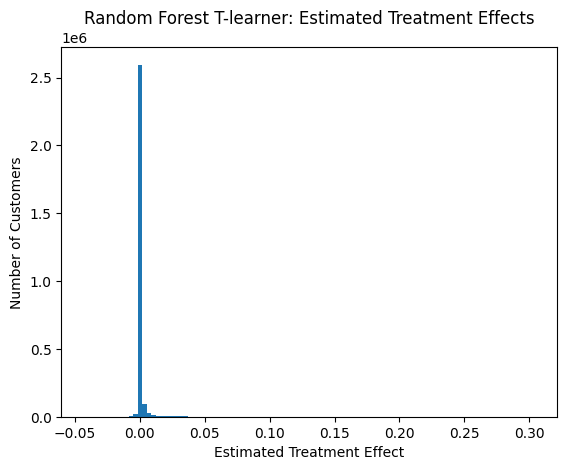

Share of customers with uplift exactly 0: 0.0


In [33]:
plt.hist(rf_ite, bins=100)

plt.xlabel('Estimated Treatment Effect')
plt.ylabel('Number of Customers')
plt.title('Random Forest T-learner: Estimated Treatment Effects')
plt.show()

print('Share of customers with uplift exactly 0:', (rf_ite == 0).mean())

### 5. Model 2: T-learner with Gradient Boosting (tuned)

- **Histogram Gradient Boosting** builds small trees sequentially, with each tree focusing on the errors of the previous trees. It uses binned feature values to make the tree-building process faster and more memory-efficient, which is useful for my large dataset.
- **Early stopping:** I set aside 10% of the training data for validation and stop adding trees if the model does not improve for 20 consecutive trees. This helps prevent overfitting.
- I tune two parameters:

  - `min_samples_leaf`: the minimum number of customers in each leaf.
  - `max_leaf_nodes`: the maximum number of leaves in each tree; larger values allow more complex trees.

In [34]:
def train_gb_classifier(X, y, min_samples_leaf, max_leaf_nodes):
    model = HistGradientBoostingClassifier(
        learning_rate=0.05,
        max_iter=500,                 # maximum number of trees
        min_samples_leaf=min_samples_leaf,
        max_leaf_nodes=max_leaf_nodes,
        early_stopping=True,
        validation_fraction=0.1,      # hold back 10% to decide when to stop
        n_iter_no_change=20,          # stop after 20 trees with no improvement
        random_state=42
    )
    model.fit(X, y)
    return model

- The function trains a Gradient Boosting model with specified tree complexity, allows up to 500 trees, and uses early stopping to stop training when additional trees no longer improve the model.

In [35]:
def train_gb_regressor(X, y, min_samples_leaf, max_leaf_nodes):
    model = HistGradientBoostingRegressor(
        learning_rate=0.05,
        max_iter=500,
        min_samples_leaf=min_samples_leaf,
        max_leaf_nodes=max_leaf_nodes,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=20,
        random_state=42
    )
    model.fit(X, y)
    return model

- This function trains a Gradient Boosting regressor with the same settings. I use it in the X-learner (Section 7) to predict estimated treatment effects, which are continuous values, not 0/1 outcomes.

- Next, I tune the Gradient Boosting models by trying different combinations of `min_samples_leaf` and `max_leaf_nodes`.
    - For each combination, I train separate treatment and control models, calculate predicted uplift on the validation set, and evaluate the results using **Qini AUC**.
    - I use Qini AUC because the goal is to identify customers who are likely to benefit from treatment, rather than simply predict conversions.
    - With the full data this loop trains 12 models on millions of customers, so it takes a while.

In [36]:
validation_data = pd.DataFrame({
    'treatment': T_val,
    'conversion': y_val,
})

start = time.time()
tuning_results = []

for leaf_size in [100, 500, 2000]:
    for leaf_nodes in [15, 31]:

        treatment_model = train_gb_classifier(X_train_treatment, y_train_treatment, leaf_size, leaf_nodes)
        control_model = train_gb_classifier(X_train_control, y_train_control, leaf_size, leaf_nodes)

        validation_data['ite'] = (
            treatment_model.predict_proba(X_val)[:, 1]
            - control_model.predict_proba(X_val)[:, 1]
        )

        tuning_results.append({
            'min_samples_leaf': leaf_size,
            'max_leaf_nodes': leaf_nodes,
            'validation_qini_auc': evaluate_model(validation_data, 'ite')['qini_auc'],
        })

print('Minutes:', round((time.time() - start) / 60, 1))

tuning_results = pd.DataFrame(tuning_results).sort_values('validation_qini_auc', ascending=False)

tuning_results

Minutes: 27.1


,min_samples_leaf,max_leaf_nodes,validation_qini_auc
1,100,31,0.000315
2,500,15,0.000303
4,2000,15,0.000298
3,500,31,0.000297
0,100,15,0.000279
5,2000,31,0.000258


In [37]:
best_settings = tuning_results.iloc[0]

best_leaf_size = int(best_settings['min_samples_leaf'])
best_leaf_nodes = int(best_settings['max_leaf_nodes'])

print('Best min_samples_leaf:', best_leaf_size)
print('Best max_leaf_nodes:', best_leaf_nodes)

Best min_samples_leaf: 100
Best max_leaf_nodes: 31


- Using the best settings from the validation step, I train separate Gradient Boosting models for the treatment and control groups and use their predictions to calculate the estimated treatment effect for each customer in the test set.

In [38]:
gb_treatment_model = train_gb_classifier(X_train_treatment, y_train_treatment, best_leaf_size, best_leaf_nodes)
gb_control_model = train_gb_classifier(X_train_control, y_train_control, best_leaf_size, best_leaf_nodes)

gb_treatment_prediction = gb_treatment_model.predict_proba(X_test)[:, 1]
gb_control_prediction = gb_control_model.predict_proba(X_test)[:, 1]

gb_ite = gb_treatment_prediction - gb_control_prediction

- Next, I calculate ROC AUC separately for the treatment and control models to assess how well each model distinguishes converters from non-converters within its respective group.

In [39]:
gb_treatment_auc = roc_auc_score(y_test[T_test == 1], gb_treatment_prediction[T_test == 1])
gb_control_auc = roc_auc_score(y_test[T_test == 0], gb_control_prediction[T_test == 0])

print('Treatment model AUC:', gb_treatment_auc)
print('Control model AUC:', gb_control_auc)

Treatment model AUC: 0.9583211042166937
Control model AUC: 0.9286356090581153


- Summary statistics of the estimated uplift for the test customers.

In [40]:
pd.Series(gb_ite).describe()

count    2.795919e+06
mean     6.075455e-04
std      1.596905e-02
min     -8.466726e-01
25%     -6.780999e-04
50%     -6.311814e-04
75%     -3.916224e-04
max      7.951494e-01
dtype: float64

- Histogram of the estimated uplift. A few extreme values would stretch the axis, so I only plot the range −0.01 to 0.01 and print the share of customers outside that range.

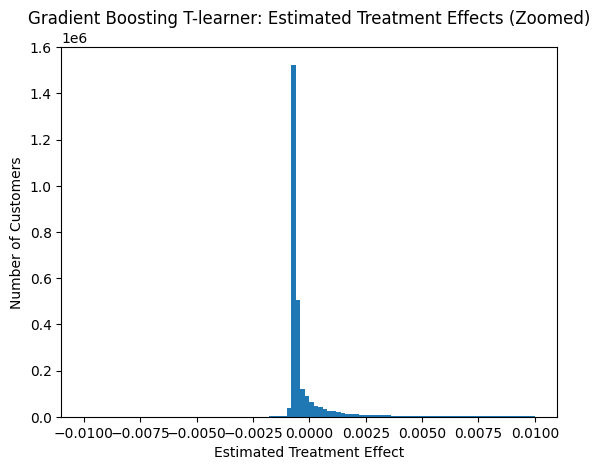

Share outside ±0.01: 0.02746681860239871


In [41]:
plt.hist(gb_ite, bins=100, range=(-0.01, 0.01))
plt.xlabel('Estimated Treatment Effect')
plt.ylabel('Number of Customers')
plt.title('Gradient Boosting T-learner: Estimated Treatment Effects (Zoomed)')
plt.show()

print('Share outside ±0.01:', (np.abs(gb_ite) > 0.01).mean())

### 6. Model 3: S-learner

- The S-learner uses **one** model for all customers, with `treatment` included as an additional feature.
- I make two predictions for each customer, one assuming treatment and one assuming no treatment, and use the difference between these predictions to estimate uplift.

Below, I add `treatment` as an additional feature to the training data and train a single Gradient Boosting model using both treatment and control customers.

I use the same tree settings (`min_samples_leaf`, `max_leaf_nodes`) that were chosen for the gradient boosting T-learner in Section 5, rather than tuning them again.

In [42]:
X_train_with_treatment = X_train.copy()
X_train_with_treatment['treatment'] = T_train

s_model = train_gb_classifier(X_train_with_treatment, y_train, best_leaf_size, best_leaf_nodes)

For each customer, the S-learner calculates:

**Predicted probability of conversion if treated** − **Predicted probability of conversion if not treated**

which is the estimated individual treatment effect (ITE) for each customer.

In [43]:
X_test_all_treated = X_test.copy()
X_test_all_treated['treatment'] = 1

X_test_all_control = X_test.copy()
X_test_all_control['treatment'] = 0

s_ite = (
    s_model.predict_proba(X_test_all_treated)[:, 1]
    - s_model.predict_proba(X_test_all_control)[:, 1]
)

print('Share of customers with uplift exactly 0:', (s_ite == 0).mean())

Share of customers with uplift exactly 0: 0.0


In [44]:
s_ite = pd.Series(s_ite)

print(s_ite.describe())

count    2.795919e+06
mean     9.361058e-04
std      5.630158e-03
min     -4.350634e-01
25%      1.726710e-05
50%      2.947314e-05
75%      1.009654e-04
max      1.823070e-01
dtype: float64


- Check for positive and negative uplift.

In [45]:
print('Share with positive uplift:', (s_ite > 0).mean())
print('Share with negative uplift:', (s_ite < 0).mean())

Share with positive uplift: 0.9706468606565498
Share with negative uplift: 0.02935313934345022


- Histogram of the S-learner's estimated uplift over the full range.

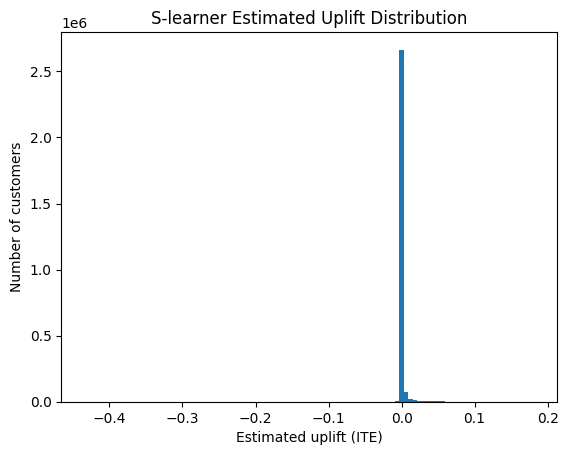

In [46]:
plt.hist(s_ite, bins=100)
plt.xlabel('Estimated uplift (ITE)')
plt.ylabel('Number of customers')
plt.title('S-learner Estimated Uplift Distribution')
plt.show()

- The same histogram zoomed in to −0.01 to 0.01, followed by summary numbers: the minimum and maximum, the share exactly 0, the share outside ±0.01, the mean, and selected percentiles.

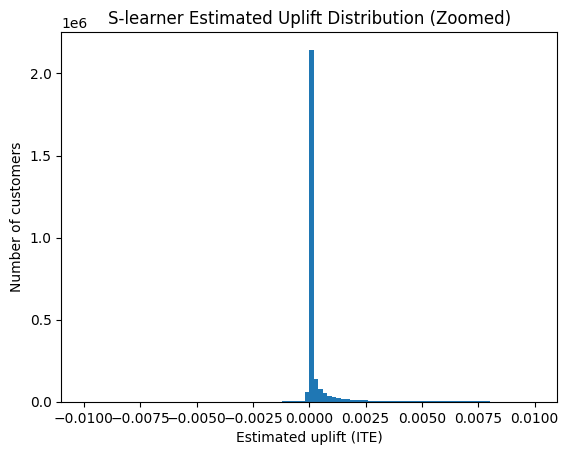

Min / max: -0.43506340695052453 0.18230696359269688
Share exactly zero: 0.0
Share outside ±0.01: 0.020341075689245647
Mean uplift: 0.0009361058140322549
Percentiles (1, 25, 50, 75, 99): [-1.38058953e-04  1.72670978e-05  2.94731354e-05  1.00965389e-04
  2.22821643e-02]


In [47]:
plt.hist(s_ite, bins=100, range=(-0.01, 0.01))
plt.xlabel('Estimated uplift (ITE)')
plt.ylabel('Number of customers')
plt.title('S-learner Estimated Uplift Distribution (Zoomed)')
plt.show()

print("Min / max:", s_ite.min(), s_ite.max())
print("Share exactly zero:", (s_ite == 0).mean())
print("Share outside ±0.01:", (np.abs(s_ite) > 0.01).mean())
print("Mean uplift:", s_ite.mean())
print("Percentiles (1, 25, 50, 75, 99):", np.percentile(s_ite, [1, 25, 50, 75, 99]))

#### Do customers that the model ranks as having higher uplift actually show greater incremental treatment effects?

In [48]:
test_results = X_test.copy()

test_results['treatment'] = T_test
test_results['conversion'] = y_test
test_results['predicted_uplift'] = np.asarray(s_ite)

Next, I divide customers into ten equal groups (deciles) by predicted uplift, from Decile 1 (highest) to Decile 10 (lowest), and compare the observed treated and control conversion rates within each group. I rank the scores before cutting them, so customers with tied scores are still split evenly across deciles. I use the same function for the baseline in Section 8. I also count the control converters in each decile, because they decide how precise each decile's uplift is.

In [49]:
def decile_table(data, score_column):
    data = data.copy()

    # Rank first so that tied scores do not break the decile cut
    ranks = data[score_column].rank(method='first')
    data['decile'] = 10 - pd.qcut(ranks, 10, labels=False)

    treated_rate = data[data['treatment'] == 1].groupby('decile')['conversion'].mean()
    control_rate = data[data['treatment'] == 0].groupby('decile')['conversion'].mean()

    table = pd.DataFrame({
        'treated_conversion': treated_rate,
        'control_conversion': control_rate
    })
    table['observed_uplift'] = table['treated_conversion'] - table['control_conversion']

    # how many control customers converted in each decile
    table['control_converters'] = data[data['treatment'] == 0].groupby('decile')['conversion'].sum()

    return table

In [50]:
decile_table(test_results, 'predicted_uplift')

,treated_conversion,control_conversion,observed_uplift,control_converters
decile,,,,
1,0.026469,0.018565,0.007904,701
2,0.001818,0.001454,0.000363,61
3,0.000642,0.000328,0.000313,14
4,0.000317,0.000117,0.000200,5
5,0.000186,0.000164,0.000022,7
6,0.000127,0.000118,0.000009,5
7,0.000084,0.000047,0.000037,2
8,0.000046,0.000024,0.000023,1
9,0.000063,0.000048,0.000015,2


### 7. Model 4: X-learner

The X-learner is designed for situations where the treatment and control groups are very different in size, as in this dataset (about 85% treated and 15% control). It builds on the two gradient boosting models from Model 2.

**Step 1. Estimate each training customer's individual treatment effect:**

- For a **treated** customer: actual outcome − outcome predicted by the control model.
- For a **control** customer: outcome predicted by the treatment model − actual outcome.

**Step 2.** Train a separate regression model for each group to predict these estimated treatment effects using the customer features. These models use the same tree settings chosen for the gradient boosting T-learner in Section 5.

**Step 3.** Combine the predictions from the two regression models using a weighted average to obtain the final estimated treatment effect.

In [51]:
# Step 1: estimate individual effects in the training data
treated_effects = y_train_treatment - gb_control_model.predict_proba(X_train_treatment)[:, 1]

control_effects = gb_treatment_model.predict_proba(X_train_control)[:, 1] - y_train_control

In [52]:
# Step 2: learn to predict these effects from the features
effect_model_treated = train_gb_regressor(X_train_treatment, treated_effects, best_leaf_size, best_leaf_nodes)

effect_model_control = train_gb_regressor(X_train_control, control_effects, best_leaf_size, best_leaf_nodes)

In Step 3, the weight is based on the share of customers in each group. Here, about 85% of customers were treated and 15% were in the control group.

- The final estimate is 0.85 × (effect model trained on control customers) + 0.15 × (effect model trained on treated customers).
- The control effect model gets the larger weight because of how its targets were built. For each control customer, the estimated effect uses a prediction from the treatment model, which was trained on about 7 million treated customers. These targets are therefore fairly reliable. The treated effect model’s targets use the control model, which was trained on far fewer customers and only about 2,400 converters, so they are noisier.

In [53]:
# Step 3: weighted average of the two predictions
weight = T_train.mean()

x_ite = (
    weight * effect_model_control.predict(X_test)
    + (1 - weight) * effect_model_treated.predict(X_test)
)

pd.Series(x_ite).describe()

count    2.795919e+06
mean     8.992439e-04
std      5.188604e-03
min     -1.355937e-01
25%      1.898238e-04
50%      1.979913e-04
75%      2.579909e-04
max      2.460975e-01
dtype: float64

- Share of customers with positive, negative and exactly zero estimated uplift under the X-learner.

In [54]:
positive_share = (x_ite > 0).mean()
negative_share = (x_ite < 0).mean()
zero_share = (x_ite == 0).mean()

print("Positive uplift:", positive_share)
print("Negative uplift:", negative_share)
print("Zero uplift:", zero_share)

Positive uplift: 0.9993937592612662
Negative uplift: 0.0006062407387338474
Zero uplift: 0.0


### 8. Comparing All Models on the Test Set

I also include a **baseline** that ranks customers by how likely they are to convert if treated. This represents the traditional **“target people most likely to buy”** approach that my research question seeks to evaluate against.

- If the uplift models do not outperform this baseline, then uplift modeling may not provide additional value for targeting.

In [55]:
results = pd.DataFrame({
    'treatment': T_test.to_numpy(),
    'conversion': y_test.to_numpy(),
    'baseline': np.asarray(gb_treatment_prediction),
    'rf_t_learner': np.asarray(rf_ite),
    'gb_t_learner': np.asarray(gb_ite),
    's_learner': np.asarray(s_ite),
    'x_learner': np.asarray(x_ite)
})

model_columns = [
    'baseline',
    'rf_t_learner',
    'gb_t_learner',
    's_learner',
    'x_learner'
]

**Check: average predicted uplift**

- The average of each model's predicted uplift should be close to the observed average effect in the test set (treated conversion rate − control conversion rate).
- A large gap would mean that a model's predictions are off overall, even if its ranking of customers is good.
- The baseline is left out, because it predicts conversion, not uplift.

In [56]:
treated_rate = results.loc[results['treatment'] == 1, 'conversion'].mean()
control_rate = results.loc[results['treatment'] == 0, 'conversion'].mean()

print('Observed average effect in the test set:', treated_rate - control_rate)
print(results[model_columns[1:]].mean())

Observed average effect in the test set: 0.0011508378971446258
rf_t_learner    0.000955
gb_t_learner    0.000608
s_learner       0.000936
x_learner       0.000899
dtype: float64


**Test-set metrics with confidence intervals**

- `bootstrap_metrics` draws 200 resamples of the test set and calculates the metrics for every model on each one.
- `evaluate_with_intervals` then shows each metric on the full test set, with its 95% interval in brackets.
- With 2.8 million test customers and five models, this takes about 15 minutes.

In [57]:
start = time.time()

boot = bootstrap_metrics(results, model_columns)

print('Minutes:', round((time.time() - start) / 60, 1))

evaluate_with_intervals(results, model_columns, boot)

Minutes: 14.4


,qini_auc,uplift@5%,uplift@10%,uplift@20%,uplift@30%,uplift@50%
baseline,"0.0004 [0.0003, 0.0005]","0.0135 [0.0106, 0.0163]","0.0082 [0.0067, 0.0097]","0.0048 [0.0040, 0.0056]","0.0035 [0.0031, 0.0040]","0.0022 [0.0020, 0.0025]"
rf_t_learner,"0.0004 [0.0003, 0.0004]","0.0137 [0.0108, 0.0164]","0.0082 [0.0066, 0.0097]","0.0049 [0.0042, 0.0056]","0.0034 [0.0029, 0.0039]","0.0022 [0.0019, 0.0025]"
gb_t_learner,"0.0003 [0.0002, 0.0003]","0.0117 [0.0092, 0.0142]","0.0071 [0.0057, 0.0083]","0.0042 [0.0034, 0.0049]","0.0030 [0.0026, 0.0035]","0.0019 [0.0016, 0.0022]"
s_learner,"0.0004 [0.0003, 0.0004]","0.0127 [0.0098, 0.0158]","0.0079 [0.0064, 0.0095]","0.0047 [0.0040, 0.0055]","0.0034 [0.0029, 0.0039]","0.0022 [0.0019, 0.0025]"
x_learner,"0.0004 [0.0003, 0.0004]","0.0136 [0.0108, 0.0165]","0.0083 [0.0069, 0.0098]","0.0045 [0.0038, 0.0053]","0.0033 [0.0028, 0.0037]","0.0022 [0.0019, 0.0024]"


**Differences from the baseline**

- `compare_to_baseline` subtracts the baseline's metrics from each uplift model's metrics, using the same resamples as above.
- A positive value means the model does better than the baseline. If the 95% interval includes 0, the model is not clearly different from the baseline.

In [58]:
compare_to_baseline(results, model_columns, boot)

,qini_auc,uplift@5%,uplift@10%,uplift@20%,uplift@30%,uplift@50%
rf_t_learner,"-0.0000 [-0.0000, 0.0000]","0.0002 [-0.0007, 0.0012]","-0.0000 [-0.0004, 0.0004]","0.0001 [-0.0001, 0.0004]","-0.0001 [-0.0002, 0.0001]","-0.0001 [-0.0002, 0.0000]"
gb_t_learner,"-0.0001 [-0.0002, -0.0001]","-0.0018 [-0.0030, -0.0005]","-0.0012 [-0.0018, -0.0006]","-0.0006 [-0.0009, -0.0003]","-0.0005 [-0.0007, -0.0003]","-0.0003 [-0.0004, -0.0002]"
s_learner,"-0.0000 [-0.0000, -0.0000]","-0.0007 [-0.0014, -0.0000]","-0.0003 [-0.0006, 0.0000]","-0.0001 [-0.0002, 0.0000]","-0.0001 [-0.0002, -0.0000]","-0.0001 [-0.0001, -0.0000]"
x_learner,"-0.0000 [-0.0001, -0.0000]","0.0001 [-0.0009, 0.0011]","0.0000 [-0.0005, 0.0005]","-0.0002 [-0.0004, -0.0000]","-0.0003 [-0.0004, -0.0001]","-0.0001 [-0.0002, 0.0000]"


**Qini curves**

- For each model, I plot the Qini curve (incremental conversions) against the share of customers targeted. To keep the plot fast, I only use every 1,000th point.
- The dashed line is random targeting: a straight line from 0 to the incremental conversions when everyone is targeted.
- The further a curve is above the dashed line, the better the model ranks customers.

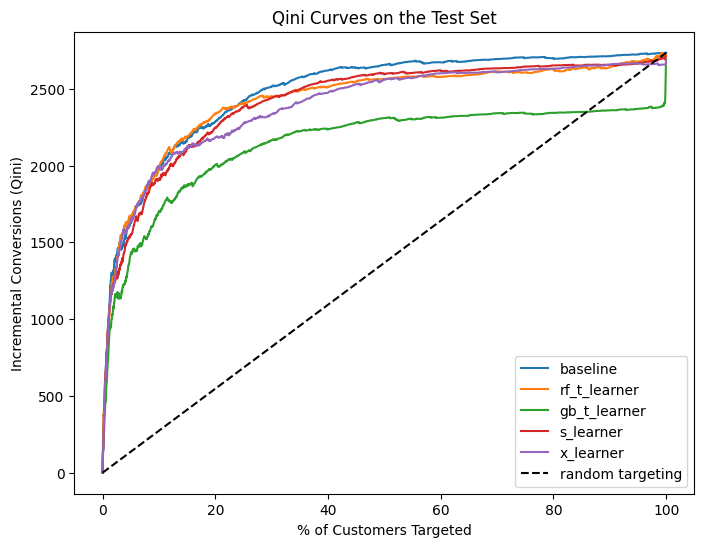

In [59]:
plt.figure(figsize=(8, 6))

for model in model_columns:
    curve = uplift_curve(results, model).iloc[::1000]
    plt.plot(curve['fraction_targeted'] * 100, curve['qini'], label=model)

baseline_curve = uplift_curve(results, 'baseline')
final_qini = baseline_curve['qini'].iloc[-1]
plt.plot([0, 100], [0, final_qini], 'k--', label='random targeting')

plt.xlabel('% of Customers Targeted')
plt.ylabel('Incremental Conversions (Qini)')
plt.title('Qini Curves on the Test Set')
plt.legend()
plt.show()

**Qini curves for the top 20%**

- With a fixed budget only the top of the ranking is targeted, so I zoom in on the first 20% of customers (every 200th point).
- The random-targeting line is cut at 20% in the same way.

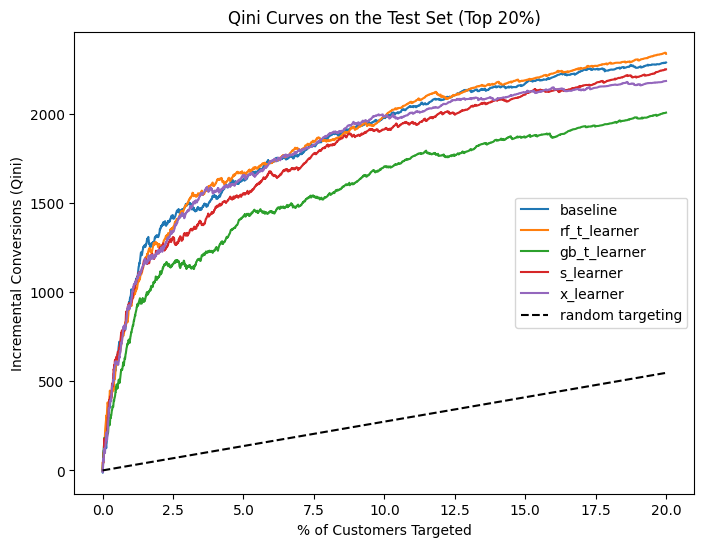

In [60]:
plt.figure(figsize=(8, 6))

for model in model_columns:
    curve = uplift_curve(results, model)
    top = curve[curve['fraction_targeted'] <= 0.20].iloc[::200]
    plt.plot(top['fraction_targeted'] * 100, top['qini'], label=model)

plt.plot([0, 20], [0, final_qini * 0.20], 'k--', label='random targeting')

plt.xlabel('% of Customers Targeted')
plt.ylabel('Incremental Conversions (Qini)')
plt.title('Qini Curves on the Test Set (Top 20%)')
plt.legend()
plt.show()

**Decile table for the baseline**

- I use the same `decile_table` function as for the S-learner in Section 6, so the two rankings can be compared decile by decile.

In [61]:
decile_table(results, 'baseline')

,treated_conversion,control_conversion,observed_uplift,control_converters
decile,,,,
1,0.027043,0.018819,0.008224,721
2,0.001917,0.001406,0.000511,58
3,0.000650,0.000211,0.000439,9
4,0.000279,0.000140,0.000139,6
5,0.000156,0.000163,-0.000007,7
6,0.000148,0.000142,0.000006,6
7,0.000097,0.000047,0.000050,2
8,0.000042,0.000071,-0.000029,3
9,0.000076,0.000000,0.000076,0


**Conversion rates among the top 10% of each ranking**

- For the top 10% of customers ranked by each model, I show the treated and control conversion rates.
- The control rate shows how often these customers convert without the campaign. A high control rate means the model's top customers are mostly likely buyers, not necessarily customers who respond most to the campaign.

In [62]:
top_10_check = []

for model in model_columns:
    curve = uplift_curve(results, model)
    row = curve.iloc[int(len(curve) * 0.10) - 1]

    top_10_check.append({
        'model': model,
        'control conversion rate (top 10%)': row['control_rate'],
        'treated conversion rate (top 10%)': row['treated_rate'],
    })

pd.DataFrame(top_10_check).set_index('model').round(4)

,control conversion rate (top 10%),treated conversion rate (top 10%)
model,,
baseline,0.0188,0.0270
rf_t_learner,0.0175,0.0258
gb_t_learner,0.0149,0.0220
s_learner,0.0186,0.0265
x_learner,0.0172,0.0255
